In [143]:
import polars as pl
from icecream import ic
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [114]:
df = pl.read_csv("../data/alibaba-2020/generated/merged_data.csv")
df.head()

worker_name,machine,start_time,end_time,machine_gpu,machine_cpu,gpu_type,cap_gpu,cap_cpu
str,str,i64,i64,f64,f64,str,i64,i64
"""8fa54171acbc9f16704c03f137ac05…","""5248e29b2b7f2b5f8b974608""",2134401,2134599,null,null,"""MISC""",8,96
"""9b69319eb5d19b4ea2514fcb4d761c…","""5248e29b2b7f2b5f8b974608""",2806218,2806331,192.551088,49.391271,"""MISC""",8,96
"""b37cd5d848323f23352464f71d3c27…","""5248e29b2b7f2b5f8b974608""",3084090,3084411,150.497242,50.949074,"""MISC""",8,96
"""8a3db37b3795c7c753963d0ef966df…","""5248e29b2b7f2b5f8b974608""",2119980,2134354,null,null,"""MISC""",8,96
"""f114ac24745ec00da7107387afc99e…","""5248e29b2b7f2b5f8b974608""",2164803,2171278,null,null,"""MISC""",8,96


In [117]:
# shift the time data
start = df["start_time"].min()
df = df.with_columns(
    pl.col("start_time").mul(1 / 60).floor().alias("start_time_min"),
    pl.col("end_time").mul(1 / 60).floor().alias("end_time_min"),
)
df = df.with_columns(pl.col("end_time_min").sub("start_time_min").alias("duration"))
df.head()

end_time_min
bool
true


In [125]:
df_gpus = df.filter(df["machine_gpu"].is_not_null())
ic(df_gpus["duration"].mean())
ic(df_gpus["machine_gpu"].mean())
ic(len(df_gpus))
df_gpus[["start_time", "machine_gpu"]].sort("start_time").head()

ic| df_gpus['duration'].mean(): 108.70891251854572
ic| df_gpus['machine_gpu'].mean(): 135.10286089986613
ic| len(df_gpus): 1767929


start_time,machine_gpu
i64,f64
2013896,379.752294
2136802,23.088949
2138656,13.319636
2138656,20.675317
2138656,10.397247


In [148]:
def make_ts(
    df: pl.DataFrame,
    start_col="start_time_min",
    end_col="end_time_min",
    value_col="machine_gpu",
):
    start_cum = df[[start_col, value_col]].group_by(start_col).sum()
    end_cum = df[[end_col, value_col]].group_by(end_col).sum()
    end_cum = end_cum.with_columns(pl.col(value_col).mul(-1.0).alias(value_col))
    # ic(start_cum)
    # ic(end_cum)

    res_df = start_cum.join(
        end_cum, left_on=start_col, right_on=end_col, how="outer_coalesce"
    )
    res_df = res_df.with_columns(
        pl.col(f"{value_col}_right").fill_null(strategy="zero"),
        pl.col(value_col).fill_null(strategy="zero"),
    )
    res_df = res_df.sort(start_col)
    res_df = res_df.with_columns(
        pl.col(value_col).add(pl.col(f"{value_col}_right")).alias("diff"),
    )

    res_df = res_df.with_columns(
        pl.col("diff").cum_sum().alias("diff_cum"),
    )

    res_df = res_df.rename({start_col: "time"})

    # res_df[value_col].fill_null(0)
    ic(res_df)

    return res_df

    # for t in start_cum:


ts = make_ts(df_gpus).sort("time")

ic| res_df: shape: (68_191, 5)
            ┌──────────┬─────────────┬───────────────────┬──────────────┬─────────────┐
            │ time     ┆ machine_gpu ┆ machine_gpu_right ┆ diff         ┆ diff_cum    │
            │ ---      ┆ ---         ┆ ---               ┆ ---          ┆ ---         │
            │ f64      ┆ f64         ┆ f64               ┆ f64          ┆ f64         │
            ╞══════════╪═════════════╪═══════════════════╪══════════════╪═════════════╡
            │ 33564.0  ┆ 379.752294  ┆ 0.0               ┆ 379.752294   ┆ 379.752294  │
            │ 35613.0  ┆ 23.088949   ┆ 0.0               ┆ 23.088949    ┆ 402.841242  │
            │ 35644.0  ┆ 238.226721  ┆ 0.0               ┆ 238.226721   ┆ 641.067963  │
            │ 35659.0  ┆ 23.870041   ┆ 0.0               ┆ 23.870041    ┆ 664.938005  │
            │ 36106.0  ┆ 37.714193   ┆ 0.0               ┆ 37.714193    ┆ 702.652197  │
            │ …        ┆ …           ┆ …                 ┆ …            ┆ …           │
 

In [161]:
def reset_start_to_zero(df: pl.DataFrame, cols: list[str]):
    mins_arr = [df[col].min() for col in cols]
    min_start = min(mins_arr)
    return df.with_columns([pl.col(col).sub(min_start) for col in cols])


ts = reset_start_to_zero(ts, ["time"])
ts.head()

time,machine_gpu,machine_gpu_right,diff,diff_cum
f64,f64,f64,f64,f64
0.0,379.752294,0.0,379.752294,379.752294
2049.0,23.088949,0.0,23.088949,402.841242
2080.0,238.226721,0.0,238.226721,641.067963
2095.0,23.870041,0.0,23.870041,664.938005
2542.0,37.714193,0.0,37.714193,702.652197


Text(0, 0.5, 'GPU Utilization')

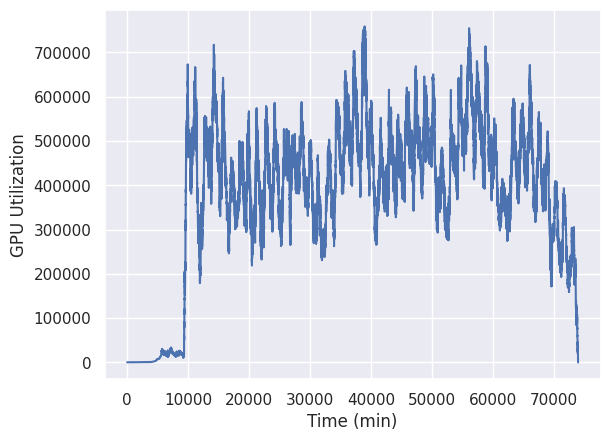

In [162]:
sns.set_theme()
sns.lineplot(x=ts["time"], y=ts["diff_cum"])
plt.xlabel("Time (min)")
plt.ylabel("GPU Utilization")

In [166]:
def minly_to_hourly(df: pl.DataFrame, time_col: str, hourly_col="time_hourly"):
    df_hourly = df.with_columns(
        [pl.col(time_col).mul(1 / 60).floor().alias(hourly_col)]
    )
    df_hourly = df_hourly.drop(time_col)
    return df_hourly.group_by(hourly_col).mean()


df_hourly = minly_to_hourly(ts, "time").sort("time_hourly")
df_hourly.head()

time_hourly,machine_gpu,machine_gpu_right,diff,diff_cum
f64,f64,f64,f64,f64
0.0,379.752294,0.0,379.752294,379.752294
34.0,95.061904,0.0,95.061904,569.615737
42.0,37.714193,0.0,37.714193,702.652197
53.0,86.885011,0.0,86.885011,789.537209
57.0,23.714426,0.0,23.714426,829.021942


<Axes: xlabel='time_hourly', ylabel='diff_cum'>

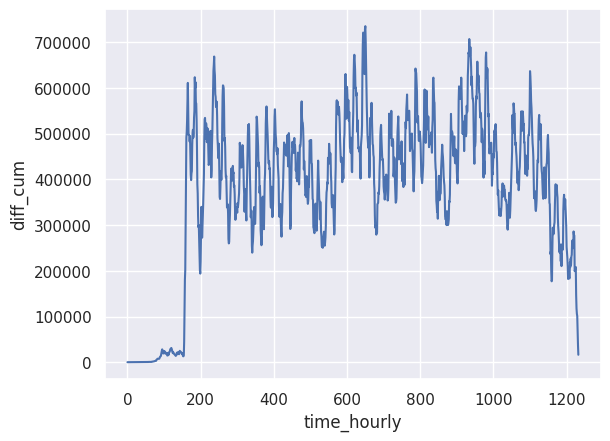

In [167]:
sns.lineplot(df_hourly, x="time_hourly", y="diff_cum")

In [ ]:
def minly_to_daily(df: pl.DataFrame, time_col: str, daily_col="time_daily"):
    df_daily = df.with_columns(
        [pl.col(time_col).mul(1 / (60 * 24)).floor().alias(daily_col)]
    )
    df_daily = df_daily.drop(time_col)
    return df_daily.group_by(daily_col).mean()